#### NLP preprocessing pipeline

the models cannot read raw arabic text, so we transform it step by step:
1. **cleaning**: remove links, diacritics (tashkeel) and tatweel
2. **tokenization**: cut the text into words
3. **stop words**: remove very common words (في، من، على ...)
4. **lemmatization** (qalsadi): give the dictionary form of a word, for example الشركات -> شركة
5. **stemming** (ISRI): cut the word to its root, for example الشركات -> شرك
6. **normalization**: write the letters in one form (أ إ آ -> ا, ى -> ي, ة -> ه)
7. **vocabulary and padding**: give a number to each word, and make all the texts the same length

we keep both lemmas and stems, then we choose one of them to train the models

In [1]:
# install once if needed:
# pip install qalsadi nltk scikit-learn
# (qalsadi also installs pyarabic and the arabic stop words list)

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import pyarabic.araby as araby
import arabicstopwords.arabicstopwords as arabicstopwords
import qalsadi.lemmatizer as qalsadi_lemmatizer
from nltk.stem.isri import ISRIStemmer
from sklearn.model_selection import train_test_split

df = pd.read_csv("../dataset/arabic_texts_scored.csv")

# we use the title and the text together
df["raw"] = df["title"] + " . " + df["text"]
print(df.shape)

(4555, 7)


##### step 1 and 2: cleaning and tokenization

In [2]:
def tokenize(text):
    text = re.sub(r"http\S+", " ", text)         # remove links
    text = araby.strip_tashkeel(text)            # remove diacritics
    text = araby.strip_tatweel(text)             # remove the elongation letter ـ
    # keep arabic words and english words, numbers and punctuation are dropped
    words = re.findall(r"[\u0621-\u064A]+|[A-Za-z]+", text)
    return [w.lower() if w.isascii() else w for w in words]

example = df["raw"][0]
print(example[:150])
print(tokenize(example)[:15])

سيري تُسقِط قائدها.. آبل تعلن رحيل رئيس الذكاء الاصطناعي بعد سنوات من الإخفاق . أعلنت شركة آبل مغادرة رئيس قسم الذكاء الاصطناعي لديها، جون جياناندريا،
['سيري', 'تسقط', 'قائدها', 'آبل', 'تعلن', 'رحيل', 'رئيس', 'الذكاء', 'الاصطناعي', 'بعد', 'سنوات', 'من', 'الإخفاق', 'أعلنت', 'شركة']


##### step 3: stop words

In [3]:
stop_words = set(arabicstopwords.stopwords_list())
print(len(stop_words), "stop words")

def remove_stop_words(tokens):
    return [w for w in tokens if w not in stop_words and len(w) > 1]

df["tokens"] = df["raw"].map(tokenize)
df["tokens_clean"] = df["tokens"].map(remove_stop_words)

print(len(df["tokens"][0]), "->", len(df["tokens_clean"][0]), "words in the first text")

13465 stop words


328 -> 253 words in the first text


##### step 4 and 5: lemmatization and stemming

the same word appears many times in the corpus, so we lemmatize each different word only once (it is much faster)

In [4]:
lemmatizer = qalsadi_lemmatizer.Lemmatizer()
stemmer = ISRIStemmer()

vocab_all = sorted({w for tokens in df["tokens_clean"] for w in tokens})
print(len(vocab_all), "different words")

lemma_of = {}
stem_of = {}
for w in vocab_all:
    if w.isascii():            # english words stay as they are
        lemma_of[w] = w
        stem_of[w] = w
    else:
        lemma_of[w] = lemmatizer.lemmatize(w) or w
        stem_of[w] = stemmer.stem(w) or w

# a few examples
for w in ["الشركات", "تطلق", "نماذج", "الاصطناعي", "يتعلمون", "للبورصة", "مصنوعة"]:
    print(w, "| lemma:", lemma_of.get(w), "| stem:", stem_of.get(w))

124077 different words


الشركات | lemma: شركة | stem: شرك
تطلق | lemma: طلق | stem: طلق
نماذج | lemma: أنموذج | stem: اذج
الاصطناعي | lemma: اصطناع | stem: صطناع
يتعلمون | lemma: تعلم | stem: علم
للبورصة | lemma: بورصة | stem: ورص
مصنوعة | lemma: مصنوع | stem: صنع


##### step 6: normalization

In [5]:
def normalize(word):
    word = re.sub("[إأآ]", "ا", word)
    word = word.replace("ى", "ي")
    word = word.replace("ة", "ه")
    return word

df["lemmas"] = df["tokens_clean"].map(lambda ts: [normalize(lemma_of[w]) for w in ts])
df["stems"] = df["tokens_clean"].map(lambda ts: [normalize(stem_of[w]) for w in ts])

# result on the first text
print("tokens :", df["tokens_clean"][0][:10])
print("lemmas :", df["lemmas"][0][:10])
print("stems  :", df["stems"][0][:10])

tokens : ['سيري', 'تسقط', 'قائدها', 'آبل', 'تعلن', 'رحيل', 'رئيس', 'الذكاء', 'الاصطناعي', 'سنوات']
lemmas : ['سير', 'اسقط', 'قائد', 'ابل', 'علن', 'رحيل', 'رئيس', 'ذكاء', 'اصطناع', 'سنه']
stems  : ['سير', 'سقط', 'قئد', 'ابل', 'تعل', 'رحل', 'رئس', 'ذكء', 'صطناع', 'سنو']


tokens (after cleaning)   125593
without stop words        124077
lemmas                    38905
stems                     30027


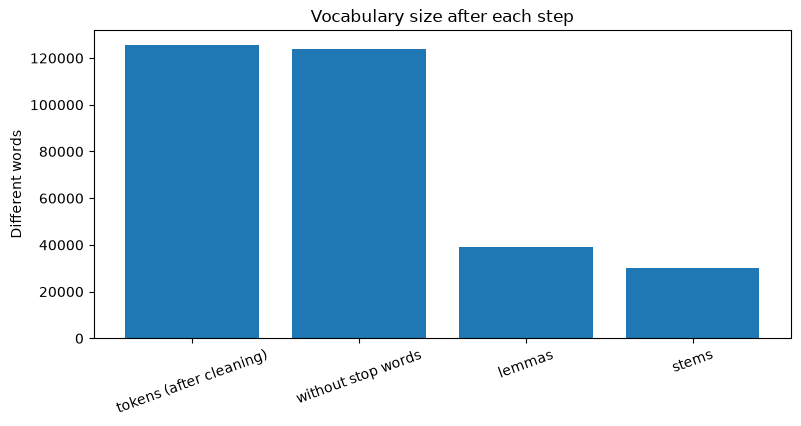

In [6]:
# how much the vocabulary is reduced by each step
sizes = {
    "tokens (after cleaning)": len({w for ts in df["tokens"] for w in ts}),
    "without stop words": len({w for ts in df["tokens_clean"] for w in ts}),
    "lemmas": len({w for ts in df["lemmas"] for w in ts}),
    "stems": len({w for ts in df["stems"] for w in ts}),
}
for name, size in sizes.items():
    print(f"{name:25s} {size}")

os.makedirs("../figures", exist_ok=True)
plt.figure(figsize=(9, 4))
plt.bar(sizes.keys(), sizes.values())
plt.xticks(rotation=20)
plt.ylabel("Different words")
plt.title("Vocabulary size after each step")
plt.savefig("../figures/vocab_size_steps.png", dpi=120, bbox_inches="tight")
plt.show()

##### step 7: train / validation / test split, vocabulary and padding

we split first, and we build the vocabulary with the train set only (so the validation and test sets do not leak into the vocabulary)

In [7]:
# which tokens do we give to the models: "lemmas" or "stems"
TOKENS = "lemmas"

idx_train, idx_temp = train_test_split(df.index, test_size=0.3, stratify=df["label"], random_state=0)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, stratify=df.loc[idx_temp, "label"], random_state=0)
print(len(idx_train), len(idx_val), len(idx_test))

# vocabulary: only the words that appear at least 2 times in the train set
counter = Counter(w for ts in df.loc[idx_train, TOKENS] for w in ts)
word2idx = {"<pad>": 0, "<unk>": 1}
for w, c in counter.items():
    if c >= 2:
        word2idx[w] = len(word2idx)
print("vocabulary size:", len(word2idx))

# length of the sequences: 95% of the train texts are shorter than this
lengths = df.loc[idx_train, TOKENS].map(len)
max_len = min(int(np.percentile(lengths, 95)), 300)
print("max_len:", max_len, "| mean length:", int(lengths.mean()))

def encode(tokens):
    ids = [word2idx.get(w, 1) for w in tokens][:max_len]   # unknown words -> 1, too long -> cut
    return ids + [0] * (max_len - len(ids))                # too short -> pad with 0

3188 683 684


vocabulary size: 19847
max_len: 300 | mean length: 600


In [8]:
def make_set(indexes):
    X = np.array([encode(ts) for ts in df.loc[indexes, TOKENS]])
    return X, df.loc[indexes, "label"].values, df.loc[indexes, "score"].values

X_train, y_train, s_train = make_set(idx_train)
X_val, y_val, s_val = make_set(idx_val)
X_test, y_test, s_test = make_set(idx_test)

print(X_train.shape, X_val.shape, X_test.shape)
print(np.bincount(y_train), np.bincount(y_val), np.bincount(y_test))
print("unknown words in the test set:", round(100 * (X_test == 1).sum() / (X_test != 0).sum(), 1), "%")

(3188, 300) (683, 300) (684, 300)
[2008  490  690] [430 105 148] [431 105 148]
unknown words in the test set: 1.5 %


In [9]:
np.savez("../dataset/processed.npz",
         X_train=X_train, y_train=y_train, s_train=s_train,
         X_val=X_val, y_val=y_val, s_val=s_val,
         X_test=X_test, y_test=y_test, s_test=s_test)

with open("../dataset/vocab.json", "w", encoding="utf-8") as f:
    json.dump(word2idx, f, ensure_ascii=False)

# also keep the preprocessed text, it is useful for the report
df_out = df[["title", "score", "label", "source"]].copy()
df_out["lemmas"] = df["lemmas"].map(" ".join)
df_out["stems"] = df["stems"].map(" ".join)
df_out.to_csv("../dataset/arabic_texts_preprocessed.csv", index=False, encoding="utf-8")
print("saved")

saved
